# Lesson 2, one call at a time

Lesson 2 prepared 2,000 customers for a model: it looked at them, filled their gaps,
flagged their outliers, scaled their numbers, encoded their categories, and then
showed two ways the preparation can leak the test set into training. This notebook
takes each of those calls one at a time, on four to ten customers, and recomputes
the worked examples of lesson 2's commentary (`Docs/data_exploration_and_preparation_commentary.md`)
with the library, so that the example worked by hand and the call that does it sit
side by side.

**How to use it.** Each section is one *atom*. Before each code cell that teaches
something there is a question under *Your prediction, before you run the next cell*:
answer it first, then run. Notebook `00_the_scikit_learn_api.ipynb` explains `fit`,
`transform` and `fit_transform` in general; this one assumes it.

Not examinable. The full-scale version of each atom is in lesson 2's notebooks
`01_exploratory_data_analysis.ipynb`, `02_scaling_encoding_and_pipelines.ipynb` and
`03_leakage_in_preprocessing.ipynb`.

## Setup

In [1]:
# Everything used here ships with the course image:
# pip install numpy==1.26.4 pandas==2.1.1 scikit-learn==1.3.1 matplotlib==3.8.0

import io

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import (MinMaxScaler, OneHotEncoder, OrdinalEncoder,
                                   StandardScaler, TargetEncoder)

np.set_printoptions(precision=3, suppress=True)
pd.set_option("display.precision", 3)

## 1. Load and look

A dataset usually arrives as a file of comma-separated values (CSV). `pd.read_csv`
reads it into a DataFrame; then four calls give the first picture: `head` (the first
rows), `info` (column types and how many values are present), `describe` (summary
statistics of the numeric columns) and `hist` (one histogram per numeric column).
Finally the table is split into the inputs `X` and the label `y`.

*From:* lesson 2, slide *Look before you touch anything* and notebook 1, section *First look: types and summary statistics*.

In [2]:
# The file, written out here so the notebook needs nothing else. An empty field is a missing value.
csv_text = """customer,age,monthly_charges,contract,satisfaction,churn
c01,,31,month-to-month,,1
c02,28,50,month-to-month,4,1
c03,31,41,month-to-month,,1
c04,,62,month-to-month,,0
c05,38,47,one-year,3,1
c06,42,70,one-year,,0
c07,,58,one-year,,0
c08,,66,one-year,5,0
c09,52,83,two-year,,0
c10,56,72,two-year,,0
"""
df = pd.read_csv(io.StringIO(csv_text))      # with a real file: pd.read_csv("customers.csv")
df.head()

,customer,age,monthly_charges,contract,satisfaction,churn
0,c01,NaN,31,month-to-month,NaN,1
1,c02,28.0,50,month-to-month,4.0,1
2,c03,31.0,41,month-to-month,NaN,1
3,c04,NaN,62,month-to-month,NaN,0
4,c05,38.0,47,one-year,3.0,1


### Your prediction, before you run the next cell

`info` reports, for each column, how many values are present. Which
column will have the fewest? And which type will pandas give `contract`?

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   customer         10 non-null     object 
 1   age              6 non-null      float64
 2   monthly_charges  10 non-null     int64  
 3   contract         10 non-null     object 
 4   satisfaction     3 non-null      float64
 5   churn            10 non-null     int64  
dtypes: float64(2), int64(2), object(2)
memory usage: 612.0+ bytes


**What to look at.** Ten rows. `age` has 6 values present and `satisfaction` only 3:
those are the gaps the next atoms deal with. `contract` and `customer` have type
`object`, pandas' name for text; every number column was recognised as a number.

In [4]:
df.describe()

,age,monthly_charges,satisfaction,churn
count,6.000,10.000,3.0,10.000
mean,41.167,58.000,4.0,0.400
std,11.179,15.804,1.0,0.516
min,28.000,31.000,3.0,0.000
25%,32.750,47.750,3.5,0.000
50%,40.000,60.000,4.0,0.000
75%,49.500,69.000,4.5,1.000
max,56.000,83.000,5.0,1.000


**What to look at.** `describe` covers the numeric columns only, and computes each
statistic over the values present: the `count` row repeats what `info` said. A `mean`
far from the median (the `50%` row) is the first sign of a skewed column or an
outlier.

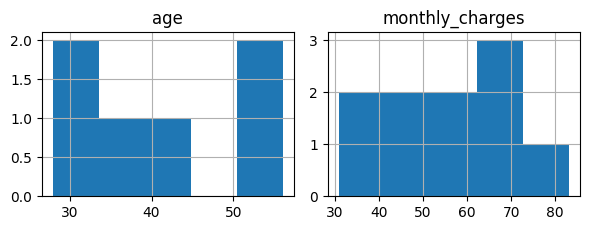

X: (10, 4)   y: (10,)   churn share: 0.4


In [5]:
df[["age", "monthly_charges"]].hist(bins=5, figsize=(6, 2.4))
plt.tight_layout()
plt.show()

X = df.drop(columns=["customer", "churn"])    # the inputs: everything except the id and the label
y = df["churn"]                                # the label, one value per row
print("X:", X.shape, "  y:", y.shape, "  churn share:", y.mean())

**What to look at.** Two histograms, then the split into inputs and label. The
customer identifier is dropped from `X` because it says who a customer is, not
anything about them; kept as a feature, a model could memorise it.

**Try changing.** read the file with `pd.read_csv(io.StringIO(csv_text), index_col="customer")`
and look at what changes in `head`.

## 2. Finding the missing values

`isna()` returns a table of `True` and `False`, one per cell: `True` where the value
is missing. Summed down the columns it counts the gaps; averaged, it gives the share
missing.

*From:* lesson 2, slide *Where the gaps are* and notebook 1, section *Missingness*.

### Your prediction, before you run the next cell

What share of `age` is missing? And how many of the ten customers have
at least one gap anywhere?

In [6]:
print("gaps per column:")
print(df.isna().sum())
print()
print("share missing per column:")
print(df.isna().mean())
print()
print("customers with at least one gap:", df.isna().any(axis=1).sum())
df[df["age"].isna()]

gaps per column:
customer           0
age                4
monthly_charges    0
contract           0
satisfaction       7
churn              0
dtype: int64

share missing per column:
customer           0.0
age                0.4
monthly_charges    0.0
contract           0.0
satisfaction       0.7
churn              0.0
dtype: float64

customers with at least one gap: 8


,customer,age,monthly_charges,contract,satisfaction,churn
0,c01,NaN,31,month-to-month,NaN,1
3,c04,NaN,62,month-to-month,NaN,0
6,c07,NaN,58,one-year,NaN,0
7,c08,NaN,66,one-year,5.0,0


**What to look at.** `age` is 40% missing, `satisfaction` 70%. Eight of the ten
customers have at least one gap, so dropping every incomplete row would leave two.
`axis=1` means "across the columns of each row"; the default, `axis=0`, works down
each column.

**Try changing.** print `df.isna()` on its own to see the table the sums are made
from.

## 3. Dropping rows and columns

`dropna` removes rows (the default) or columns (`axis=1`) that contain gaps.
`subset` restricts the check to some columns; `thresh=k` keeps a row or column only if
it has at least `k` values present.

*From:* lesson 2, slide *What to do about a gap*.

### Your prediction, before you run the next cell

How many rows survive `df.dropna()`? And which columns survive
`df.dropna(axis=1, thresh=5)`?

In [7]:
print("all rows with no gap anywhere:      ", df.dropna().shape)
print("rows with no gap in age:            ", df.dropna(subset=["age"]).shape)
print("columns with no gap at all:         ", list(df.dropna(axis=1).columns))
print("columns with at least 5 values:     ", list(df.dropna(axis=1, thresh=5).columns))
clean = df.drop(columns=["satisfaction"])        # drop one column by name
print("after dropping satisfaction, rows with no gap:", clean.dropna().shape)

all rows with no gap anywhere:       (2, 6)
rows with no gap in age:             (6, 6)
columns with no gap at all:          ['customer', 'monthly_charges', 'contract', 'churn']
columns with at least 5 values:      ['customer', 'age', 'monthly_charges', 'contract', 'churn']
after dropping satisfaction, rows with no gap: (6, 5)


**What to look at.** Dropping every incomplete row keeps 2 customers of 10.
Dropping the `satisfaction` column first, which is 70% missing, and then the
incomplete rows keeps 6. The order of the two decisions matters. Dropping rows is safe
only when the gaps are few and happen at random (missing completely at random, MCAR):
otherwise the customers left are no longer a fair sample.

**Try changing.** try `thresh=3` and `thresh=7` on the columns.

## 4. Mean imputation: four ages out of ten

`SimpleImputer(strategy="mean")` learns the mean of the values present in `fit`
and writes it into every gap in `transform`. The average stays put, but every filled
value sits exactly on the average, so the column's spread shrinks and its correlation
with other columns weakens. The commentary works this out on ten customers; here
are the same ten, with the full ages known so the loss can be measured.

*From:* lesson 2, slide *What mean imputation actually costs*; commentary, worked example *four ages out of ten*.

In [8]:
age_full = np.array([24, 28, 31, 35, 38, 42, 45, 49, 52, 56], dtype=float)
charges = np.array([31, 50, 41, 62, 47, 70, 58, 66, 83, 72], dtype=float)
age_seen = df["age"].to_numpy()                  # the same ages, with 24, 35, 45 and 49 missing
print("full ages:", age_full)
print("seen ages:", age_seen)

full ages: [24. 28. 31. 35. 38. 42. 45. 49. 52. 56.]
seen ages: [nan 28. 31. nan 38. 42. nan nan 52. 56.]


### Your prediction, before you run the next cell

Four ages of ten are missing, $p = 0.4$. The rule of thumb from the
slide says the variance keeps about $1 - p = 0.6$ of its value and the correlation about
$\sqrt{0.6} = 0.77$. What value will fill the gaps, and how close will the ten
customers come to those two ratios?

In [9]:
imputer = SimpleImputer(strategy="mean").fit(age_seen.reshape(-1, 1))
age_filled = imputer.transform(age_seen.reshape(-1, 1)).ravel()
print("statistics_ (the fill value):", imputer.statistics_.round(1))
print("filled ages:", age_filled.round(1))
print()
v0, v1 = age_full.var(), age_filled.var()
r0, r1 = np.corrcoef(age_full, charges)[0, 1], np.corrcoef(age_filled, charges)[0, 1]
print(f"variance of age:    {v0:.1f} -> {v1:.1f}   ratio {v1 / v0:.2f}")
print(f"correlation with charges: {r0:.3f} -> {r1:.3f}   ratio {r1 / r0:.2f}")
print(f"mean age: {age_full.mean():.1f} -> {age_filled.mean():.1f}")

statistics_ (the fill value): [41.2]
filled ages: [41.2 28.  31.  41.2 38.  42.  41.2 41.2 52.  56. ]

variance of age:    102.0 -> 62.5   ratio 0.61
correlation with charges: 0.860 -> 0.676   ratio 0.79
mean age: 40.0 -> 41.2


**What to look at.** The gaps are filled with **41.2**, the mean of the six ages
present. The variance falls from 102.0 to 62.5, a ratio of **0.61**, and the correlation
with monthly charges from 0.860 to 0.676, a ratio of **0.79**: about a fifth of the
relationship is gone, while the mean moved by little more than a year. These are the
commentary's numbers; on ten values they depend on which four went missing, and the
slide's formula is their average over many draws.

**Try changing.** use `strategy="median"` and compare the fill value and the two
ratios.

## 5. The missing indicator: keeping the fact of the gap

Imputing hides where the gaps were. `SimpleImputer(add_indicator=True)` adds one
column of 0 and 1 per column that had gaps in `fit`, so a model can still see that a
value was missing. It helps only when being missing says something the other columns
do not: when the gaps are missing not at random (MNAR).

*From:* lesson 2, slides *What to do about a gap* and *Choosing among the four*.

### Your prediction, before you run the next cell

The imputer is fitted on `age` and `monthly_charges`. How many columns
will `transform` return?

In [10]:
imputer = SimpleImputer(strategy="mean", add_indicator=True)
out = imputer.fit_transform(df[["age", "monthly_charges"]])
print("columns out:", imputer.get_feature_names_out())
print(out.round(1))

columns out: ['age' 'monthly_charges' 'missingindicator_age']
[[41.2 31.   1. ]
 [28.  50.   0. ]
 [31.  41.   0. ]
 [41.2 62.   1. ]
 [38.  47.   0. ]
 [42.  70.   0. ]
 [41.2 58.   1. ]
 [41.2 66.   1. ]
 [52.  83.   0. ]
 [56.  72.   0. ]]


**What to look at.** Three columns: the two inputs, filled, and one indicator for
`age`, the only column of the two with gaps when the imputer was fitted. A column with
no gaps in `fit` gets no indicator, even if a later test row has a gap there. On lesson
2's churn data the indicator made the area under the curve slightly worse, 0.751 to
0.741: the gaps were not informative.

**Try changing.** add `satisfaction` to the two columns: which indicators appear?

## 6. Outliers: the ruler made of the outlier, and the same eight values

Two rules flag a value as an outlier. The **z-score** rule measures its distance
from the mean in standard deviations and flags beyond 3. The **interquartile range**
(IQR) rule measures from the quartiles $Q_1$ and $Q_3$ (the values a quarter and three
quarters of the way up the sorted data) and flags beyond $1.5 \times IQR$ outside them.

*From:* lesson 2, slides *Rule 1: distance in standard deviations* and *Rule 2: interquartile range (IQR)*; commentary, worked examples *the ruler made of the outlier* and *the same eight values*.

In [11]:
charges8 = pd.Series([40, 45, 50, 55, 60, 65, 70, 500], dtype=float)   # 500 is a data-entry error
charges8.describe()

count      8.000
mean     110.625
std      157.649
min       40.000
25%       48.750
50%       57.500
75%       66.250
max      500.000
dtype: float64

### Your prediction, before you run the next cell

The 500 is obviously wrong. Will the z-score rule flag it? Will the IQR
rule?

In [12]:
z = (charges8 - charges8.mean()) / charges8.std()       # pandas std divides by n - 1
print("mean", round(charges8.mean(), 1), "  standard deviation", round(charges8.std(), 1),
      "  without the 500:", round(charges8[:-1].std(), 1))
print("z-scores:", z.round(2).tolist())
print("flagged by |z| > 3:", charges8[z.abs() > 3].tolist())
print("largest z possible with 8 values, (n - 1) / sqrt(n):", round(7 / np.sqrt(8), 2))
print()
q1, q3 = charges8.quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print(f"Q1 {q1:.2f}  Q3 {q3:.2f}  IQR {iqr:.2f}  fences {low:.2f} and {high:.2f}")
print("flagged by the IQR rule:", charges8[(charges8 < low) | (charges8 > high)].tolist())

mean 110.6   standard deviation 157.6   without the 500: 10.8
z-scores: [-0.45, -0.42, -0.38, -0.35, -0.32, -0.29, -0.26, 2.47]
flagged by |z| > 3: []
largest z possible with 8 values, (n - 1) / sqrt(n): 2.47

Q1 48.75  Q3 66.25  IQR 17.50  fences 22.50 and 92.50
flagged by the IQR rule: [500.0]


**What to look at.** The z-score of 500 is **2.47**, below 3, so the first rule flags
nothing: the error inflated the standard deviation from 10.8 to 157.6, the very ruler
it was measured with. With eight values no z-score can exceed 2.47, whatever the data.
The quartiles barely notice the 500 (48.75 and 66.25), the fences are 22.50 and 92.50,
and the IQR rule flags it. These are the commentary's numbers, recomputed here by the
library.

**Try changing.** add twenty ordinary values between 40 and 70 and check whether the
z-score rule now catches the 500.

## 7. Two scalers, five customers, one outlier

`MinMaxScaler` maps the smallest value to 0 and the largest to 1. `StandardScaler`
subtracts the mean and divides by the standard deviation. Both learn their two numbers
in `fit`; an outlier moves both.

*From:* lesson 2, slide *StandardScaler vs MinMaxScaler*; commentary, worked example *five customers, one outlier*.

In [13]:
five = np.array([[20.0], [50.0], [80.0], [120.0], [3300.0]])

### Your prediction, before you run the next cell

After `MinMaxScaler`, where will the four ordinary customers sit inside
the range 0 to 1?

In [14]:
mm = MinMaxScaler().fit(five)
st = StandardScaler().fit(five)
print("MinMax learned data_min_", mm.data_min_, "data_max_", mm.data_max_)
print("Standard learned mean_", st.mean_.round(0), "scale_", st.scale_.round(0))
pd.DataFrame({"charge": five.ravel(),
              "MinMax": mm.transform(five).ravel().round(3),
              "Standard": st.transform(five).ravel().round(2)})

MinMax learned data_min_ [20.] data_max_ [3300.]
Standard learned mean_ [714.] scale_ [1293.]


,charge,MinMax,Standard
0,20.0,0.000,-0.54
1,50.0,0.009,-0.51
2,80.0,0.018,-0.49
3,120.0,0.030,-0.46
4,3300.0,1.000,2.00


**What to look at.** MinMax packs the four ordinary customers into the bottom
**3%** of the range: 20 and 120 end up 0.030 apart. Standard scaling squeezes them too,
between −0.54 and −0.46, but the outlier lands at 2.00, two units away, rather than
taking the whole range. Neither scaler removes an outlier; deciding what to do with it
comes first.

**Try changing.** remove the 3300 and compare both columns again.

## 8. Correlations with `corr`

`df.corr()` computes the correlation of every pair of numeric columns: +1 when
they rise together on a straight line, −1 when one falls as the other rises, 0 when
no straight-line relationship exists. With gaps, each pair uses the rows where both
values are present.

*From:* lesson 2, notebook 1, section *Correlations*.

### Your prediction, before you run the next cell

Which pair of columns will show the strongest correlation, and will
churn be positively or negatively correlated with age?

In [15]:
corr_cols = ["age", "monthly_charges", "churn"]
df[corr_cols].corr()

,age,monthly_charges,churn
age,1.000,0.856,-0.866
monthly_charges,0.856,1.000,-0.858
churn,-0.866,-0.858,1.000


**What to look at.** Every pair is strong on these few rows. Age and monthly charges
move together, 0.856, computed on the six customers with an age. Churn falls as age
rises, −0.866, and as charges rise, −0.858: on these ten customers, the older and the
higher-paying ones churned less. On ten customers each value is fragile; lesson 2's
notebook computes the same table on 2,000. A correlation measures only straight-line
association, and says nothing about cause.

**Try changing.** compare with `np.corrcoef` on the full ages of atom 4,
`np.corrcoef(age_full, charges)`.

## 9. Standardisation by hand, and the test set

Standardising means $z = (x - \bar x) / s$, with $\bar x$ and $s$ the mean and
standard deviation of the **training** rows. The test rows are transformed with the
same two numbers, never with their own.

*From:* lesson 2, slide *Why scale?* and notebook 2, section *Split first, as Lesson 1 insisted*.

In [16]:
train_charges = charges[:7].reshape(-1, 1)     # seven customers to train on
test_charges = charges[7:].reshape(-1, 1)      # three new ones
print("train:", train_charges.ravel(), "  test:", test_charges.ravel())

train: [31. 50. 41. 62. 47. 70. 58.]   test: [66. 83. 72.]


### Your prediction, before you run the next cell

Computed by hand from the seven training charges, what are the mean and
the standard deviation? Will `StandardScaler` agree to the last digit?

In [17]:
mean = train_charges.mean()
sd = np.sqrt(((train_charges - mean) ** 2).mean())        # divide by m, as scikit-learn does
print(f"by hand: mean {mean:.3f}, standard deviation {sd:.3f}")
scaler = StandardScaler().fit(train_charges)
print(f"scaler:  mean_ {scaler.mean_[0]:.3f}, scale_ {scaler.scale_[0]:.3f}")
print()
print("test, by hand:  ", ((test_charges - mean) / sd).ravel().round(3))
print("test, transform:", scaler.transform(test_charges).ravel().round(3))
print("test, WRONG fit on itself:", StandardScaler().fit_transform(test_charges).ravel().round(3))

by hand: mean 51.286, standard deviation 12.232
scaler:  mean_ 51.286, scale_ 12.232

test, by hand:   [1.203 2.593 1.693]
test, transform: [1.203 2.593 1.693]
test, WRONG fit on itself: [-1.089  1.326 -0.237]


**What to look at.** Hand and library agree: the scaler is two numbers and one
subtraction and division. The test customers, transformed with the training numbers,
come out above 1: they pay more than the average training customer, which is true.
Refitted on themselves they come out centred on 0, as if they were average, and the
model would read them wrongly.

**Try changing.** compute the standard deviation with pandas,
`pd.Series(train_charges.ravel()).std()`: pandas divides by $m - 1$, and the number no
longer matches the scaler's.

## 10. One step size for two directions

Gradient descent takes steps of size $\eta$ (the learning rate, written $\alpha$ from
lesson 3 on) against the slope. On the cost $J(w) = \tfrac12(100\,w_1^2 + w_2^2)$ one
direction is 100 times steeper than the other, as when one feature's values are ten
times larger than another's. Each step multiplies $w_1$ by $1 - 100\eta$ and $w_2$ by
$1 - \eta$.

*From:* lesson 2, slides *Unequal scales: a narrow valley* and *A 100:1 variance ratio, and what it costs*; commentary, worked example *one step size for two directions*.

### Your prediction, before you run the next cell

The steep direction forces $\eta$ below $2/100 = 0.02$. At $\eta = 0.019$,
how many steps will it take $w_2$ to fall to 1% of where it started: about 10, 50 or
250?

In [18]:
eta = 0.019
w = np.array([1.0, 1.0])
steps = 0
while abs(w[1]) > 0.01:
    gradient = np.array([100 * w[0], 1 * w[1]])
    w = w - eta * gradient
    steps += 1
print(f"steps for w2 to fall below 1%: {steps}   (w1 after them: {w[0]:.1e})")

# Standardised: both curvatures equal 1, and a step of 1 lands on the minimum at once.
w = np.array([1.0, 1.0])
w = w - 1.0 * np.array([1 * w[0], 1 * w[1]])
print("standardised, one step of size 1:", w)
print("unstandardised, eta = 0.021, five steps of w1:",
      [round((1 - 100 * 0.021) ** k, 3) for k in range(1, 6)])

steps for w2 to fall below 1%: 241   (w1 after them: -9.4e-12)
standardised, one step of size 1: [0. 0.]
unstandardised, eta = 0.021, five steps of w1: [-1.1, 1.21, -1.331, 1.464, -1.611]


**What to look at.** **241 steps**: the steep direction sets the largest safe step,
and the shallow one crawls at 0.981 per step. With equal curvatures one step of size 1
reaches the minimum. And just above the limit, at 0.021, $w_1$ is multiplied by −1.1
each step: it overshoots further every time and never reaches the minimum, which is called
divergence. Nothing about the
model changed between the two runs, only the units of the inputs.

**Try changing.** set the ratio to 10 instead of 100, with $\eta = 0.19$, and count the
steps again.

## 11. Three encodings of the same ten customers

A category must become a number before a model can use it. **Ordinal** encoding
gives each category an integer, 0, 1, 2. **One-hot** encoding gives each category its
own column of 0 and 1. **Target** encoding replaces each category with the average
label of its customers, here the churn rate.

*From:* lesson 2, slides *One customer, three encodings* and *Ordinal: equal steps, unequal churn*; commentary, worked examples *ten customers, three encodings* and *the steps ordinal encoding assumes equal*.

In [19]:
contracts = df[["contract"]]
print(pd.concat([contracts, y], axis=1).to_string(index=False))

      contract  churn
month-to-month      1
month-to-month      1
month-to-month      1
month-to-month      0
      one-year      1
      one-year      0
      one-year      0
      one-year      0
      two-year      0
      two-year      0


### Your prediction, before you run the next cell

What churn rate will target encoding give each contract? And how far
apart will ordinal encoding put month-to-month and one-year, compared with one-year and
two-year?

In [20]:
order = [["month-to-month", "one-year", "two-year"]]
ordinal = OrdinalEncoder(categories=order).fit_transform(contracts)
onehot = OneHotEncoder(categories=order, sparse_output=False).fit(contracts)
rates = y.groupby(df["contract"]).mean()          # target encoding, by hand: mean churn per contract

table = pd.DataFrame(onehot.transform(contracts), columns=onehot.get_feature_names_out())
table.insert(0, "contract", df["contract"])
table["ordinal"] = ordinal.ravel()
table["target"] = df["contract"].map(rates)
table["churn"] = y
table

,contract,contract_month-to-month,contract_one-year,contract_two-year,ordinal,target,churn
0,month-to-month,1.0,0.0,0.0,0.0,0.75,1
1,month-to-month,1.0,0.0,0.0,0.0,0.75,1
2,month-to-month,1.0,0.0,0.0,0.0,0.75,1
3,month-to-month,1.0,0.0,0.0,0.0,0.75,0
4,one-year,0.0,1.0,0.0,1.0,0.25,1
5,one-year,0.0,1.0,0.0,1.0,0.25,0
6,one-year,0.0,1.0,0.0,1.0,0.25,0
7,one-year,0.0,1.0,0.0,1.0,0.25,0
8,two-year,0.0,0.0,1.0,2.0,0.00,0
9,two-year,0.0,0.0,1.0,2.0,0.00,0


**What to look at.** Ordinal and one-hot are computed from the category alone. The
target column is computed **from the labels**: 3/4 = 0.75 for month-to-month, 1/4 = 0.25
for one-year, 0 for two-year. That is what makes it powerful, and it is what atoms 15
and 16 break.

### Your prediction, before you run the next cell

Ordinal encoding puts the three contracts one unit apart. What are the
two steps in churn rate?

In [21]:
print("churn rates:", rates.round(3).to_dict())
print("month-to-month -> one-year:", rates["month-to-month"] - rates["one-year"])
print("one-year -> two-year:      ", rates["one-year"] - rates["two-year"])

churn rates: {'month-to-month': 0.75, 'one-year': 0.25, 'two-year': 0.0}
month-to-month -> one-year: 0.5
one-year -> two-year:       0.25


**What to look at.** The steps are **0.50** and **0.25**: the data asks for one
step twice the other, the same shape as the real rates on the slide, 0.129 and 0.066.
Ordinal encoding gives both steps the length 1, so a linear model must predict the same
change for both. One-hot gives each contract its own coefficient and assumes
nothing.

**Try changing.** pass the categories in another order to `OrdinalEncoder`, for
example two-year first, and see the integers change while the data does not.

## 12. Four rows, four columns, rank three

One-hot encoding makes one column of 0 and 1 per category; these are often called
*dummy* columns. With an intercept, keeping a dummy for every category makes the
columns dependent: in every row the dummies add up to 1, which is the intercept
column. The
**rank** of a matrix counts its independent columns; when it is smaller than the
number of columns, infinitely many sets of coefficients make the same predictions.

*From:* lesson 2, slides *One one-hot column too many* and *4 columns, but only rank 3*; commentary, worked example *four rows, four columns, rank three*.

In [22]:
four = pd.DataFrame({"contract": ["month-to-month", "one-year", "two-year", "one-year"]})
dummies = OneHotEncoder(categories=order, sparse_output=False).fit_transform(four)
X4 = np.column_stack([np.ones(4), dummies])     # intercept column, then d1, d2, d3
print(X4)

[[1. 1. 0. 0.]
 [1. 0. 1. 0.]
 [1. 0. 0. 1.]
 [1. 0. 1. 0.]]


### Your prediction, before you run the next cell

Four rows and four columns. What rank will NumPy report? And after
`drop="first"`?

In [23]:
print("rank with all three dummies:", np.linalg.matrix_rank(X4), "of", X4.shape[1], "columns")
w = np.array([0.1, 0.6, 0.3, 0.0])                 # some coefficients
w_shifted = w + np.array([5, -5, -5, -5])          # add 5 to the intercept, take 5 from every dummy
print("same predictions?", X4 @ w, X4 @ w_shifted)

dropped = OneHotEncoder(categories=order, drop="first", sparse_output=False).fit(four)
X3 = np.column_stack([np.ones(4), dropped.transform(four)])
print("columns kept:", dropped.get_feature_names_out(), " rank:", np.linalg.matrix_rank(X3), "of", X3.shape[1])

rank with all three dummies: 3 of 4 columns
same predictions? [0.7 0.4 0.1 0.4] [0.7 0.4 0.1 0.4]
columns kept: ['contract_one-year' 'contract_two-year']  rank: 3 of 3


**What to look at.** Rank **3**, not 4: one column is a sum of others. Adding 5 to
the intercept and taking 5 from every dummy changes no prediction, so the coefficients
cannot be pinned down. `drop="first"` removes the month-to-month column, the rank equals
the number of columns again, and month-to-month becomes the reference the other
coefficients are measured from. scikit-learn's linear models still fit without it, by
choosing one solution; the coefficients just stop meaning anything on their own.

**Try changing.** drop the intercept column instead of a dummy and check the rank.

## 13. `ColumnTransformer`: a different preparation for each column

A table has number columns and category columns, which need different steps.
`ColumnTransformer` sends each list of columns through its own transformer and joins
the results side by side. Put inside a pipeline with a model, the whole preparation is
fitted with one `fit`, on the training rows only.

*From:* lesson 2, slides *ColumnTransformer + Pipeline* and *The code*; notebook 2, section *`ColumnTransformer` + `Pipeline`*.

### Your prediction, before you run the next cell

The number columns go through an imputer and a scaler, `contract`
through one-hot. How many columns will come out, and what happens to `satisfaction`,
which is in neither list?

In [24]:
prep = ColumnTransformer([
    ("numbers", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), ["age", "monthly_charges"]),
    ("categories", OneHotEncoder(handle_unknown="ignore"), ["contract"]),
])                                                 # columns in neither list are dropped
out = prep.fit_transform(X)
print("columns out:", prep.get_feature_names_out())
print(out.round(2))

columns out: ['numbers__age' 'numbers__monthly_charges'
 'categories__contract_month-to-month' 'categories__contract_one-year'
 'categories__contract_two-year']
[[-0.09 -1.8   1.    0.    0.  ]
 [-1.6  -0.53  1.    0.    0.  ]
 [-1.22 -1.13  1.    0.    0.  ]
 [-0.09  0.27  1.    0.    0.  ]
 [-0.34 -0.73  0.    1.    0.  ]
 [ 0.16  0.8   0.    1.    0.  ]
 [-0.09  0.    0.    1.    0.  ]
 [-0.09  0.53  0.    1.    0.  ]
 [ 1.43  1.67  0.    0.    1.  ]
 [ 1.93  0.93  0.    0.    1.  ]]


**What to look at.** Five columns: two scaled numbers and three contract dummies,
named by the step that made them. `satisfaction` is dropped, the default for columns
not listed (`remainder="drop"`). `handle_unknown="ignore"` makes a contract never seen
in `fit` come out as all zeros instead of raising an error.

### Your prediction, before you run the next cell

Put `prep` and a logistic regression in one pipeline and fit it. Where
does the median used to fill `age` come from?

In [25]:
model = make_pipeline(prep, LogisticRegression()).fit(X, y)
print("median learned for age:", model[0].named_transformers_["numbers"][0].statistics_[0])
print("churn probability for the first three customers:", model.predict_proba(X)[:3, 1].round(2))

median learned for age: 40.0
churn probability for the first three customers: [0.85 0.78 0.85]


**What to look at.** The median comes from the rows passed to `fit`; here that
is all ten, because this atom shows the mechanics and has no test set. In lesson 2 the
same pipeline is fitted on the training split, so the test customers never touch the
median, the scaler or the encoder.

**Try changing.** add `remainder="passthrough"` and see `satisfaction` come through
with its gaps.

## 14. The area under the curve, by counting pairs

The area under the receiver operating characteristic (ROC) curve, the **AUC**,
asks one question of a model's scores: take one churner and one customer who stayed,
at random; how often does the churner get the higher score? 1 is a perfect ranking, 0.5
is no better than chance.

*From:* lesson 2, slide *The model, on churn*; commentary, worked example *the AUC by counting pairs*.

In [26]:
churner_scores = [0.7, 0.4]
stayer_scores = [0.6, 0.3, 0.2]

### Your prediction, before you run the next cell

There are 2 × 3 = 6 pairs of one churner and one stayer. How many are
ordered correctly, and what is the AUC?

In [27]:
pairs = [(c, s) for c in churner_scores for s in stayer_scores]
right = sum(c > s for c, s in pairs)
print("pairs:", pairs)
print(f"ordered correctly: {right} of {len(pairs)} = {right / len(pairs):.2f}")

labels = [1, 1, 0, 0, 0]
scores = churner_scores + stayer_scores
print("roc_auc_score:", round(roc_auc_score(labels, scores), 2))
print("a model giving everyone the same score:", roc_auc_score(labels, [0.5] * 5))

pairs: [(0.7, 0.6), (0.7, 0.3), (0.7, 0.2), (0.4, 0.6), (0.4, 0.3), (0.4, 0.2)]
ordered correctly: 5 of 6 = 0.83
roc_auc_score: 0.83
a model giving everyone the same score: 0.5


**What to look at.** **5 of 6** pairs, AUC **0.83**, the same from the count and from
`roc_auc_score`. The only pair wrong is the churner at 0.4 against the stayer at 0.6. A
model that gives everyone the same score, like the majority baseline, orders no pair and
gets 0.5, however high its accuracy: on lesson 2's churn data the baseline's accuracy
is 0.806. `roc_auc_score` takes the true labels first and the *scores* second, the
probabilities from `predict_proba`, not the labels from `predict`.

**Try changing.** swap the churner's 0.4 for 0.65 and count again.

## 15. Leak 1: the two nearest neighbours are both in the test set

`KNNImputer` fills a gap with the average of the $k$ most similar rows. Fitted
on all the rows, it can fill a training row with values taken from test rows: no label
is touched, no error is raised, and the test set has leaked into training.

*From:* lesson 2, slide *Leak 1: impute before splitting*; commentary, worked example *the two nearest neighbours are both in the test set*.

In [28]:
six = pd.DataFrame({"tenure": [10, 30, 41, 70, 42, 39],
                    "age": [34, 52, np.nan, 61, 45, 47]},
                   index=list("ABCDEF"))
split = pd.Series(["train"] * 4 + ["test"] * 2, index=six.index)
six.assign(split=split)

,tenure,age,split
A,10,34.0,train
B,30,52.0,train
C,41,NaN,train
D,70,61.0,train
E,42,45.0,test
F,39,47.0,test


### Your prediction, before you run the next cell

Customer C, in training, has no age; tenure 41. With $k = 2$, which
two customers will lend C their age if the imputer is fitted on all six? And if it is
fitted on the four training rows only?

In [29]:
leaky = KNNImputer(n_neighbors=2).fit(six)                    # WRONG: test rows included
honest = KNNImputer(n_neighbors=2).fit(six[split == "train"])  # RIGHT: training rows only
print("C's age, imputer fitted on all six:     ", leaky.transform(six.loc[["C"]])[0, 1])
print("C's age, imputer fitted on training only:", honest.transform(six.loc[["C"]])[0, 1])

C's age, imputer fitted on all six:      46.0
C's age, imputer fitted on training only: 56.5


**What to look at.** Fitted on all six, C gets **46.0**, the average of E and F
(tenure 42 and 39), both test customers. Fitted on the training rows, C gets **56.5**,
from B and D. The first version copies the test customers' features into a training
row, and the model is then graded on those same customers. Lesson 2's notebook counts
the same thing at scale: 94 of 128 imputed rows borrowed from the test set.

**Try changing.** set `n_neighbors=3` and see which donors each version picks.

## 16. Leak 2: a zip code with no signal, and an AUC of 0.875

Target encoding computed on all rows puts each row's own label inside its own
feature. With few customers per category, that share is large, and a useless column
starts to look predictive.

*From:* lesson 2, slides *Leak 2: encode before splitting* and *How much of its own label a row sees*; commentary, worked example *a zip code with no signal, and an AUC of 0.875*.

In [30]:
zips = pd.DataFrame({"zip": list("AABBCCDD"), "churn": [1, 1, 0, 0, 1, 0, 0, 1]})
zips

,zip,churn
0,A,1
1,A,1
2,B,0
3,B,0
4,C,1
5,C,0
6,D,0
7,D,1


### Your prediction, before you run the next cell

The labels were set without looking at the zip code, so the code carries
nothing. Encode each zip by the churn rate of its two customers, using all eight rows:
what AUC will the encoded column reach against the labels?

In [31]:
zips["encoded_all_rows"] = zips.groupby("zip")["churn"].transform("mean")
print(zips.to_string(index=False))
print("AUC of the encoded column:", roc_auc_score(zips["churn"], zips["encoded_all_rows"]))

zip  churn  encoded_all_rows
  A      1               1.0
  A      1               1.0
  B      0               0.0
  B      0               0.0
  C      1               0.5
  C      0               0.5
  D      0               0.5
  D      1               0.5
AUC of the encoded column: 0.875


**What to look at.** **0.875** from a column with nothing in it. Zips A and B are
encoded 1 and 0, exactly their own customers' labels; with two customers per code, each
customer's own label is half of their own feature. The leak shrinks as the groups grow,
as $1/n_c$ for groups of $n_c$ customers, which is why lesson 2's `zip_code`, with about
four customers per code, is the column that breaks.

**Try changing.** give every zip four customers instead of two, with labels from a
coin, and watch the AUC fall towards 0.5.

## 17. The fix: the same eight customers, cross-fitted, and `TargetEncoder`

**Cross-fitting** encodes each row using only the *other* rows: split the rows into
folds, and encode each fold with the churn rates computed on the remaining folds. A row
never sees its own label. scikit-learn's `TargetEncoder` does this inside
`fit_transform`.

*From:* lesson 2, slide *The fix*; commentary, worked example *the same eight customers, cross-fitted*; notebook 3, section *Leak 2*.

### Your prediction, before you run the next cell

Two folds, one customer of each zip in each, so each customer is encoded by
the other member of its pair. What AUC will the honest column reach?

In [32]:
folds = [[0, 2, 4, 6], [1, 3, 5, 7]]
encoded = np.zeros(8)
for k, fold in enumerate(folds):
    other = zips.iloc[folds[1 - k]]
    rates_other = other.groupby("zip")["churn"].mean()
    encoded[fold] = zips.iloc[fold]["zip"].map(rates_other)
zips["cross_fitted"] = encoded
print(zips[["zip", "churn", "encoded_all_rows", "cross_fitted"]].to_string(index=False))
print("AUC, cross-fitted:", roc_auc_score(zips["churn"], zips["cross_fitted"]))

zip  churn  encoded_all_rows  cross_fitted
  A      1               1.0           1.0
  A      1               1.0           1.0
  B      0               0.0           0.0
  B      0               0.0           0.0
  C      1               0.5           0.0
  C      0               0.5           1.0
  D      0               0.5           1.0
  D      1               0.5           0.0
AUC, cross-fitted: 0.5


**What to look at.** AUC **0.500**: with no shared label, the column is worth
nothing, as it should be. On groups this small an honest score can even land below 0.5,
because each customer is described by a neighbour who may disagree with them; that is
noise, and it averages out on real group sizes.

### Your prediction, before you run the next cell

`TargetEncoder` on forty customers in twenty zip codes, labels from a coin.
`fit_transform(X, y)` and `fit(X, y).transform(X)`: will they give the same column?

In [33]:
rng = np.random.default_rng(0)
zip40 = pd.DataFrame({"zip": np.repeat([f"z{i:02d}" for i in range(20)], 2)})
churn40 = rng.integers(0, 2, size=40)

encoder = TargetEncoder(random_state=0)
cross_fitted = encoder.fit_transform(zip40, churn40).ravel()   # each row encoded without its own fold
plain = encoder.transform(zip40).ravel()                       # every row encoded with all rows
print("AUC, fit_transform (cross-fitted):", round(roc_auc_score(churn40, cross_fitted), 3))
print("AUC, transform after fit (leaky): ", round(roc_auc_score(churn40, plain), 3))

AUC, fit_transform (cross-fitted): 0.55
AUC, transform after fit (leaky):  0.896


**What to look at.** They differ, and this is the one place in scikit-learn
where `fit_transform(X, y)` is **not** `fit(X, y).transform(X)`. `fit_transform`
cross-fits, with five folds by default, and gives an honest column near 0.5; `transform`
uses the encodings learned from all rows, which is right for new rows (the test set)
and leaky for the rows the encoder was fitted on, 0.896 here. Inside a pipeline this is
handled for you: `fit` uses `fit_transform`, and `predict` uses `transform` on the test
rows.

**Try changing.** repeat the forty-customer cell with `default_rng(1)` to `(4)`: the
leaky AUC stays high every time, the cross-fitted one wanders around 0.5.